<a href="https://colab.research.google.com/github/AstronomekDomansky/-.-1/blob/main/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практическая работа 6. Подготовка набора данных

Это **первый отчётный ноутбук** курса. Он закрывает практики **1–5**. Второй отчёт (практика 16) будет по практикам 7–15.

**Предметная задача.** IT-компания ведёт журнал обращений в службу поддержки (service desk): сбои продуктов, нагрузка на серверы, эскалации. По этим данным позже можно учить модель, которая заранее замечает **нарушение SLA** (Service Level Agreement - когда набор данных или пайплайн его доставки перестает соответствовать заранее согласованным обязательствам (гарантиям качества и доступности))(`sla_breached`: 1 — срок ответа сорван, 0 — уложились). В этой работе модель **не строится**. Нужно осмотреть, посчитать, нарисовать и привести таблицу в порядок — как на практиках 1–5.

Официальная формулировка занятия: загрузка → разведочный анализ и визуализация → предобработка → конструирование признаков. У нас те же шаги разложены на **пять блоков**, по одной пройденной практике.

---

### Что входит в работу (14 баллов)

| Блок | Практика | Что сдаёте | Баллы |
|------|----------|------------|------:|
| 1 | Основы pandas | код осмотра, выборки и нового столбца + вопросы | 2,5 |
| 2 | NumPy | код на массивах (срез, маска, broadcasting) + вопросы | 2,5 |
| 3 | Группировка | `groupby`, `pivot_table`, дата из Unix + вопросы | 3 |
| 4 | Визуализация | не меньше 4 графиков разных типов и выводы | 3 |
| 5 | Подготовка данных | пропуски, текст, кодирование, масштаб, новые признаки + вопросы | 3 |
| | | **Итого** | **14** |

Код без запуска и пустые ответы на вопросы не засчитываются. Числа и графики у каждого свои: датасет строится из вашего ФИО и номера в списке.

---

### Важно: у каждого студента свой набор данных

Данные **не скачиваются с Kaggle**. Они генерируются из персонального `SEED`. Заполните ячейку с фамилией, прежде чем запускать остальные.


## Шаг 0. Персонализация (обязательно)

Впишите **фамилию, имя** и **номер по списку группы**. Из них считается `SEED` — зерно генератора, которое задаёт ваш вариант.


In [1]:
# ==========================================================
# ⬇️  ЗАПОЛНИТЕ ЭТИ ТРИ ПОЛЯ СВОИМИ ДАННЫМИ
# ==========================================================
last_name   = "Арутюнян"    # <-- впишите свою фамилию
first_name  = "Дмитрий"      # <-- впишите своё имя
list_number = 2           # <-- ваш номер по списку (целое число)
# ==========================================================

import hashlib

def make_seed(last: str, first: str, number: int) -> int:
    # ФИО + номер -> стабильный seed 0..99999
    key = f"{last.strip().lower()}|{first.strip().lower()}|{int(number)}"
    return int(hashlib.sha256(key.encode("utf-8")).hexdigest(), 16) % 100_000

SEED = make_seed(last_name, first_name, list_number)

print("Студент:", last_name, first_name, f"(№{list_number})")
print("Ваш персональный SEED:", SEED)
print("Запишите SEED в итоговый отчёт — он подтверждает вариант.")


Студент: Арутюнян Дмитрий (№2)
Ваш персональный SEED: 36390
Запишите SEED в итоговый отчёт — он подтверждает вариант.


In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)


In [3]:
#@title Создание персонального датасета (нажмите ▶️) { display-mode: "form" }

def load_it_tickets(seed: int, n: int = 1800) -> "pd.DataFrame":
    """Индивидуальный «грязный» журнал IT-обращений по seed."""
    rng = np.random.default_rng(seed)

    opened_ts = rng.integers(1_735_689_600, 1_751_241_600, size=n)
    department = rng.choice(
        ["Support", "Backend", "DevOps", "Security", "Data"],
        size=n, p=[0.32, 0.22, 0.18, 0.14, 0.14],
    )
    product = rng.choice(
        ["Cloud", "CRM", "Billing", "Auth", "Analytics"], size=n
    )
    priority = rng.choice(
        ["Low", "Medium", "High", "Critical"], size=n, p=[0.40, 0.30, 0.20, 0.10]
    )
    channel = rng.choice(["Email", "Slack", "Portal", "Phone"], size=n)
    assignee = rng.choice(["Junior", "Middle", "Senior"], size=n, p=[0.35, 0.45, 0.20])
    tier = rng.choice(["Free", "Pro", "Enterprise"], size=n, p=[0.45, 0.40, 0.15])
    cpu_pct = np.clip(np.round(rng.normal(48, 18, size=n), 1), 1, 99)
    memory_mb = np.clip(np.round(rng.normal(2200, 850, size=n), 0), 256, None)
    n_reopens = rng.poisson(0.7, size=n)
    comments = rng.poisson(4.0, size=n) + 1
    resolve_hours = np.clip(np.round(rng.lognormal(1.55, 0.75, size=n), 2), 0.2, 240)

    logit = (
        -1.4
        + 1.4 * (priority == "Critical")
        + 0.7 * (priority == "High")
        - 0.4 * (priority == "Low")
        + 0.035 * resolve_hours
        + 0.018 * cpu_pct
        + 0.55 * (department == "Security")
        + 0.35 * (n_reopens >= 2)
        - 0.45 * (assignee == "Senior")
        - 0.30 * (tier == "Enterprise")
    )
    sla = (rng.uniform(size=n) < 1 / (1 + np.exp(-logit))).astype(int)

    df = pd.DataFrame({
        "ticket_id": np.arange(10_000, 10_000 + n),
        "opened_ts": opened_ts,
        "department": department,
        "product": product,
        "priority": priority,
        "channel": channel,
        "assignee_level": assignee,
        "client_tier": tier,
        "cpu_pct": cpu_pct,
        "memory_mb": memory_mb,
        "n_reopens": n_reopens,
        "comments": comments,
        "resolve_hours": resolve_hours,
        "sla_breached": sla,
    })

    df.loc[rng.choice(n, int(0.06 * n), replace=False), "resolve_hours"] = np.nan
    df.loc[rng.choice(n, int(0.04 * n), replace=False), "cpu_pct"] = np.nan
    df.loc[rng.choice(n, int(0.03 * n), replace=False), "comments"] = np.nan
    df.loc[rng.choice(n, 10, replace=False), "resolve_hours"] *= 9
    df.loc[rng.choice(n, 8, replace=False), "memory_mb"] *= 7
    ridx = rng.choice(n, int(0.12 * n), replace=False)
    df.loc[ridx, "department"] = df.loc[ridx, "department"].str.upper()
    pidx = rng.choice(n, int(0.08 * n), replace=False)
    df.loc[pidx, "product"] = "  " + df.loc[pidx, "product"].str.lower() + " "
    df = pd.concat([df, df.sample(int(0.025 * n), random_state=seed)], ignore_index=True)
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

print("Функция load_it_tickets готова.")


Функция load_it_tickets готова.


In [4]:
df_raw = load_it_tickets(SEED)

print("Ваш датасет создан. Размер:", df_raw.shape)
print("Доля нарушений SLA:", f"{df_raw['sla_breached'].mean():.1%}")


Ваш датасет создан. Размер: (1845, 14)
Доля нарушений SLA: 44.2%


---
# Этап 1. Основы pandas (практика 1)

**Цель.** Убедиться, что таблица загрузилась, понять размер и типы, выбрать строки и столбцы, добавить признак, сохранить фрагмент.

### Пример

Стандартный осмотр и простая выборка. Запустите ячейки — те же команды понадобятся в задании.


In [5]:
print("Размер (строки, столбцы):", df_raw.shape)
print("Имена столбцов:", list(df_raw.columns))
print("\nПервые 5 строк:")
display(df_raw.head())
print("\nТипы и непропуски:")
df_raw.info()


Размер (строки, столбцы): (1845, 14)
Имена столбцов: ['ticket_id', 'opened_ts', 'department', 'product', 'priority', 'channel', 'assignee_level', 'client_tier', 'cpu_pct', 'memory_mb', 'n_reopens', 'comments', 'resolve_hours', 'sla_breached']

Первые 5 строк:


,ticket_id,opened_ts,department,product,priority,channel,assignee_level,client_tier,cpu_pct,memory_mb,n_reopens,comments,resolve_hours,sla_breached
0,11747,1749778657,DevOps,Auth,Low,Phone,Middle,Enterprise,97.0,1982.0,1,5.0,5.74,0
1,10498,1747451354,BACKEND,Analytics,Medium,Email,Middle,Pro,81.6,3871.0,0,NaN,NaN,0
2,11798,1746270023,Support,Analytics,Low,Phone,Junior,Pro,47.6,1569.0,1,8.0,2.37,0
3,10627,1749975882,Backend,CRM,Low,Phone,Junior,Enterprise,40.6,2006.0,1,8.0,1.72,0
4,11516,1745730831,Backend,CRM,Medium,Portal,Junior,Pro,59.4,2678.0,0,7.0,5.38,1



Типы и непропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1845 entries, 0 to 1844
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ticket_id       1845 non-null   int64  
 1   opened_ts       1845 non-null   int64  
 2   department      1845 non-null   object 
 3   product         1845 non-null   object 
 4   priority        1845 non-null   object 
 5   channel         1845 non-null   object 
 6   assignee_level  1845 non-null   object 
 7   client_tier     1845 non-null   object 
 8   cpu_pct         1771 non-null   float64
 9   memory_mb       1845 non-null   float64
 10  n_reopens       1845 non-null   int64  
 11  comments        1791 non-null   float64
 12  resolve_hours   1736 non-null   float64
 13  sla_breached    1845 non-null   int64  
dtypes: float64(4), int64(4), object(6)
memory usage: 201.9+ KB


In [6]:
# loc — по подписям, iloc — по номерам
print("Один столбец (первые значения priority):")
print(df_raw["priority"].head())
print("\nДве строки и три столбца через loc:")
display(df_raw.loc[0:1, ["ticket_id", "department", "priority"]])
print("Критические тикеты:", (df_raw["priority"] == "Critical").sum())


Один столбец (первые значения priority):
0       Low
1    Medium
2       Low
3       Low
4    Medium
Name: priority, dtype: object

Две строки и три столбца через loc:


,ticket_id,department,priority
0,11747,DevOps,Low
1,10498,BACKEND,Medium


Критические тикеты: 185


### Задание 1

В ячейках ниже, **на своих данных**:

1. Выведите **последние 8 строк** (`.tail(8)`).
2. Посчитайте **число полных дубликатов** (`.duplicated().sum()`).
3. Через `.loc` отберите тикеты с `priority` равным `"High"` **или** `"Critical"` и столбцы `ticket_id`, `department`, `priority`, `resolve_hours`. Сколько таких строк?
4. Добавьте столбец `is_slow`: `True`, если `resolve_hours` больше 24 (пропуски пусть останутся пропусками). Затем **переименуйте** `n_reopens` в `reopen_count`.
5. Сохраните первые 100 строк текущего `df_raw` в файл `it_tickets_head.csv`.


In [7]:
# ВАШ КОД (Задание 1)

# 1. Последние 8 строк
print("Последние 8 строк (хвост файла):")
display(df_raw.tail(8))


Последние 8 строк (хвост файла):


,ticket_id,opened_ts,department,product,priority,channel,assignee_level,client_tier,cpu_pct,memory_mb,n_reopens,comments,resolve_hours,sla_breached
1837,10064,1737413622,Security,Billing,Low,Phone,Junior,Free,37.0,1861.0,1,4.0,13.28,0
1838,11345,1745381224,Backend,Billing,High,Portal,Middle,Free,58.2,3043.0,1,5.0,2.07,1
1839,11103,1740124306,Security,Auth,Critical,Phone,Middle,Free,65.0,2084.0,0,4.0,7.21,1
1840,11440,1743182812,Support,Cloud,Medium,Email,Junior,Free,71.0,2342.0,1,5.0,9.90,1
1841,11468,1737638784,Backend,Billing,Critical,Email,Junior,Enterprise,63.6,459.0,0,6.0,3.17,1
1842,11502,1741010663,SUPPORT,CRM,Medium,Portal,Senior,Free,30.5,1374.0,2,7.0,1.83,0
1843,10777,1739740575,DevOps,CRM,Medium,Email,Junior,Enterprise,47.9,3760.0,0,6.0,9.58,0
1844,10039,1742065231,Data,Auth,Medium,Phone,Middle,Pro,48.5,2117.0,0,5.0,7.72,1


In [8]:
# 2. Число дубликатов
n_dups = df_raw.duplicated().sum()
print(f"Число полных дубликатов строк: {n_dups}")
print(f"Доля дубликатов: {n_dups / len(df_raw):.2%}")

Число полных дубликатов строк: 45
Доля дубликатов: 2.44%


In [9]:
# 3. High или Critical, выбранные столбцы
print("Количество строк:")
subset = df_raw.loc[(df_raw["priority"]=="High" ) | (df_raw["priority"]=="Critical"), ["ticket_id", "department", "priority","resolve_hours"]]
len(subset)
#добавить выборку по столбцу исполнитель= Senior.
subset1 = df_raw.loc[(df_raw["priority"]=="High" ) | (df_raw["priority"]=="Critical") | (df_raw["assignee_level"]=="Senior"), ["ticket_id", "department", "priority","resolve_hours"]]
len(subset1)


Количество строк:


787

In [10]:
# 4. Столбец is_slow и переименование n_reopens → reopen_count
df_raw["is_slow"] = (df_raw["resolve_hours"] > 24).astype(bool)
df_raw[["is_slow", "resolve_hours"]].head(15)

df_raw.rename(columns={"n_reopens" : "reopen_count"}, inplace=True)
df_raw[["is_slow", "reopen_count"]].head(15)



,is_slow,reopen_count
0,False,1
1,False,0
2,False,1
3,False,1
4,False,0
5,False,0
6,False,1
7,False,1
8,False,2
9,False,0


In [11]:
# 5. Сохранение it_tickets_head.csv
df_raw.to_csv("it_tickets_head.csv", index=False)
print("Сохранено it_tickets_head.csv, строк:", len(df_raw))

# КОНЕЦ ВАШЕГО КОДА


Сохранено it_tickets_head.csv, строк: 1845


**Контрольные вопросы к этапу 1** (ответьте текстом):

1. Чем `.info()` отличается от `.describe()`? Что показывает каждый?
2. Когда удобнее `.loc`, а когда `.iloc`?
3. Почему дубликаты строк могут испортить и статистику, и будущую модель?


*Ответы (двойной клик):*

1.Методы решают разные задачи: один про структуру таблицы, другой про распределение чисел.

.info() : имена и типы столбцов, число непустых значений (пропуски), память.

.describe() : count, mean, std, min, 25/50/75 %, max. Только по числовым (bool → 0/1, строки игнорирует).

2.loc — выборка по меткам (именам строк и столбцов):

срез df.loc[0:4] включает и строку 0, и строку 4 (правая граница включается);

удобен, когда фильтруете по значениям столбцов или знаете имена: df.loc[mask, ["temp", "humidity"]].

.iloc — выборка по позициям (целочисленным индексам):

работает как обычный срез Python: df.iloc[:5, :3] берёт первые 5 строк и первые 3 столбца, правая граница не включается;

удобен, когда нужны «первые N строк», «последние два столбца» и неважны имена.

3.Проблема 1. Искажение статистики.
Дублированные строки дают своим значениям искусственный перевес. Средние, медианы, доли категорий, стандартные отклонения смещаются в сторону продублированных наблюдений.

Проблема 2. Утечка данных (leakage).
Если дубликат попадёт одновременно в обучающую и тестовую выборки, модель фактически «подсмотрит ответ» на тесте.

Проблема 3. Искажение весов классов.
Дубликаты редкого класса могут «раздуть» его долю и сбить балансировку.

Проблема 4. Переобучение.
Модель тратит ёмкость на запоминание повторов вместо изучения закономерностей, что повышает дисперсию и ухудшает обобщение.


---
# Этап 2. NumPy

**Цель.** Перевести столбец в массив, посчитать агрегаты без цикла `for`, срезать, отфильтровать маской, сделать поэлементную операцию (broadcasting).

Таблица удобна, когда у столбцов есть имена. Массив удобен, когда нужно быстро посчитать «все значения сразу».


### Пример


In [12]:
cpu = df_raw["cpu_pct"].to_numpy(dtype=float)
print("Тип:", type(cpu), "форма:", cpu.shape, "dtype:", cpu.dtype)
print("Первые 8 значений:", cpu[:8])
print("Среднее без учёта NaN:", np.nanmean(cpu))
print("Максимум:", np.nanmax(cpu))

# маска: загрузка выше 80% (NaN даст False)
high_cpu = cpu > 80
print("Доля наблюдений с CPU > 80%:", np.nanmean(high_cpu))

# broadcasting: перевод % в долю 0..1
cpu_share = cpu / 100
print("Доля CPU, первые 5:", cpu_share[:5])


Тип: <class 'numpy.ndarray'> форма: (1845,) dtype: float64
Первые 8 значений: [97.  81.6 47.6 40.6 59.4 60.8 14.6 60.4]
Среднее без учёта NaN: 49.37577639751553
Максимум: 99.0
Доля наблюдений с CPU > 80%: 0.044444444444444446
Доля CPU, первые 5: [0.97  0.816 0.476 0.406 0.594]


### Задание 2

Работайте с массивами, не с циклами `for` по строкам.

1. Соберите массивы `hours` из `resolve_hours` и `mem` из `memory_mb` (тип `float`).
2. Посчитайте **медиану** и **стандартное отклонение** `hours`, игнорируя NaN.
3. Срезом возьмите **последние 15** значений `mem`.
4. Постройте маску «память выше 4000 МБ» и выведите, **сколько** таких тикетов (для NaN считайте «не выше»).
5. Сделайте z-оценку памяти через broadcasting: `(mem - mean) / std`, где mean и std без NaN. Выведите 5 первых z-оценок.


In [13]:
#  ВАШ КОД (Задание 2)

# 1. Массивы hours и mem
hours = df_raw["resolve_hours"].to_numpy(dtype=float)
mem   = df_raw["memory_mb"].to_numpy(dtype=float)

print("hours — тип:", type(hours), "| форма:", hours.shape, "| dtype:", hours.dtype)
print("mem   — тип:", type(mem),   "| форма:", mem.shape,   "| dtype:", mem.dtype)

hours — тип: <class 'numpy.ndarray'> | форма: (1845,) | dtype: float64
mem   — тип: <class 'numpy.ndarray'> | форма: (1845,) | dtype: float64


In [14]:
# 2. Медиана и std для hours

hours_median = np.nanmedian(hours)
hours_std    = np.nanstd(hours)

print(f"Медиана resolve_hours (без NaN): {hours_median:.2f} ч")
print(f"Стандартное отклонение (без NaN): {hours_std:.2f} ч")


Медиана resolve_hours (без NaN): 4.62 ч
Стандартное отклонение (без NaN): 6.73 ч


In [15]:
# 3. Срез последних 15 значений mem
mem_last15 = mem[-15:]

print("Последние 15 значений memory_mb:")
print(mem_last15)

Последние 15 значений memory_mb:
[3312. 2156. 1785. 1954. 2669.  535. 2214. 1861. 3043. 2084. 2342.  459.
 1374. 3760. 2117.]


In [16]:
# 4. Маска памяти > 4000
mask_mem = mem > 4000
n_high_mem = np.sum(mask_mem)
print("Тикетов с памятью > 4000 МБ:", n_high_mem)
print("Доля от всех:", n_high_mem / len(mem))

Тикетов с памятью > 4000 МБ: 42
Доля от всех: 0.022764227642276424


In [17]:
# 5. Z-оценка памяти
mean_mem = np.nanmean(mem)
std_mem  = np.nanstd(mem)
# 5 случайных значений из массива mem
print("5 случайных значений из массива mem:")
print(np.random.choice(mem, size=5, replace=False))

z_mem = (mem - mean_mem) / std_mem
print("Среднее (без NaN):", mean_mem)
print("Std (без NaN):", std_mem)
print("Первые 5 z-оценок:")
print(z_mem[:5])
#  КОНЕЦ ВАШЕГО КОДА


5 случайных значений из массива mem:
[2164. 1222.  912. 1157. 3529.]
Среднее (без NaN): 2301.3783197831976
Std (без NaN): 1390.9694211544977
Первые 5 z-оценок:
[-0.22960844  1.12843723 -0.52652367 -0.21235429  0.27076201]


**Контрольные вопросы к этапу 2:**

1. Чем массив NumPy принципиально отличается от списка Python?
2. Что такое broadcasting? Приведите пример из этого задания.
3. Почему для среднего по столбцу с пропусками нужен `np.nanmean`, а не `np.mean`?


*Ответы:*

1.Чем массив NumPy принципиально отличается от списка Python?

Тип элементов. Список хранит ссылки на объекты разных типов. Массив NumPy хранит элементы одного типа подряд в памяти.

Скорость. Операции над массивом выполняются векторизованно на уровне C, без интерпретации каждой итерации Python. На миллионе элементов разница — десятки–сотни раз.

Форма. Массив многомерный, фиксированной формы . Список — одномерный; для 2D нужны вложенные списки.

Память. Массив компактнее: хранит значения, а не объекты Python.

Цена. Массив менее гибок: разнотипные данные в один массив не положишь.


2. Что такое broadcasting?

Broadcasting — правило NumPy, которое позволяет делать арифметику над массивами разных, но совместимых форм без явного копирования. Меньший массив «растягивается» по осям большего.

Пример из пункта 5:

z_mem = (mem - mean_mem) / std_mem
mem — массив формы (1845,), mean_mem и std_mem — скаляры. NumPy сам вычитает одно и то же среднее из каждого элемента и делит на одно и то же std — без цикла for.

3.Почему np.nanmean, а не np.mean?

np.mean не игнорирует NaN: по правилам IEEE любое число + NaN = NaN, поэтому результат тоже NaN.

a = np.array([1.0, 2.0, np.nan, 4.0])
np.mean(a)      # nan
np.nanmean(a)   # 2.333...  — NaN пропущен, делим на 3
np.nanmean маскирует пропуски: складывает только валидные значения и делит на их количество.



---
# Этап 3. Агрегирование и группировка (практика 3)

**Цель.** Ответить на вопросы вида «какая доля нарушений SLA **в каждом** отделе?» без ручного фильтра. Схема одна: разбить → посчитать → собрать.

Unix-время `opened_ts` нужно превратить в обычную дату, иначе группировка по дням невозможна.


### Пример


In [18]:
print("Среднее время решения по приоритету:")
display(
    df_raw.groupby("priority")["resolve_hours"].agg(["count", "mean", "median"]).round(2)
)

print("\nСводная: доля нарушений SLA по отделу и уровню исполнителя")
pivot = pd.pivot_table(
    df_raw, values="sla_breached", index="department",
    columns="assignee_level", aggfunc="mean",
)
display(pivot.round(3))


Среднее время решения по приоритету:


,count,mean,median
priority,,,
Critical,173,5.76,4.54
High,315,5.97,4.45
Low,725,6.37,4.80
Medium,523,6.11,4.46



Сводная: доля нарушений SLA по отделу и уровню исполнителя


assignee_level,Junior,Middle,Senior
department,,,
BACKEND,0.583,0.407,0.500
Backend,0.493,0.494,0.361
DATA,0.625,0.200,0.500
DEVOPS,0.538,0.643,0.750
Data,0.375,0.411,0.244
DevOps,0.423,0.423,0.407
SECURITY,0.444,0.625,0.500
SUPPORT,0.360,0.471,0.250
Security,0.605,0.585,0.414


In [19]:
df_time = df_raw.copy()
df_time["opened_at"] = pd.to_datetime(df_time["opened_ts"], unit="s")
print("Минимум и максимум даты:", df_time["opened_at"].min(), df_time["opened_at"].max())
print("Тикетов по месяцам:")
print(df_time.groupby(df_time["opened_at"].dt.to_period("M")).size())


Минимум и максимум даты: 2025-01-01 05:09:03 2025-06-29 23:49:48
Тикетов по месяцам:
opened_at
2025-01    332
2025-02    246
2025-03    341
2025-04    300
2025-05    310
2025-06    316
Freq: M, dtype: int64


### Задание 3

1. Сделайте `groupby` по `product`: для каждого продукта — число тикетов, среднее `cpu_pct`, доля `sla_breached`. Отсортируйте по доле нарушений **по убыванию**.
2. Постройте `pivot_table`: строки — `channel`, столбцы — `priority`, значения — среднее `resolve_hours`.
3. Переведите `opened_ts` в datetime. Добавьте столбец `opened_date` (только дата). Посчитайте число тикетов **по дням** и выведите 5 дней с наибольшим числом обращений.
4. Дополнительно: `groupby` по `client_tier` с `.agg` сразу по нескольким столбцам — среднее `resolve_hours` и сумма `sla_breached`.


In [20]:
#  ВАШ КОД (Задание 3)

# 1. groupby по product
product_stats = df_raw.groupby('product').agg(
    ticket_count=('ticket_id', 'count'),
    avg_cpu=('cpu_pct', 'mean'),
    sla_breach_rate=('sla_breached', 'mean')
).sort_values('sla_breach_rate', ascending=False)

print("Статистика по продуктам (сортировка по доле нарушений SLA):")
display(product_stats.round(3))


Статистика по продуктам (сортировка по доле нарушений SLA):


,ticket_count,avg_cpu,sla_breach_rate
product,,,
cloud,23,52.110,0.565
Auth,330,49.319,0.482
CRM,345,48.786,0.467
billing,30,46.630,0.467
Cloud,331,48.851,0.447
auth,30,50.731,0.433
Analytics,343,50.411,0.420
Billing,348,49.761,0.399
crm,32,49.568,0.375


In [21]:
#Многоуровневые столбцы
multi_level_df=df_raw.groupby("department").agg({"resolve_hours": ["mean", "median", "max"],"cpu_pct":["mean","max"]})
display(multi_level_df.round(3))

resolve_hours                cpu_pct      
                    mean median     max    mean   max
department                                           
BACKEND            6.372  4.510   45.17  52.490  88.5
Backend            5.883  4.200   34.47  49.387  99.0
DATA               5.605  4.500   17.98  48.342  89.5
DEVOPS             7.268  5.685   17.30  45.251  88.3
Data               5.420  4.010   22.03  48.987  99.0
DevOps             6.433  4.600   96.84  50.789  98.9
SECURITY           6.630  5.965   12.82  42.123  67.6
SUPPORT            5.041  4.030   18.63  46.760  99.0
Security           7.269  5.245  170.19  49.109  95.8
Support            6.112  4.740   45.99  49.786  99.0

In [22]:
# 2. pivot_table channel × priority
pivot_channel_priority = pd.pivot_table(
    df_raw,
    values="resolve_hours",
    index="channel",
    columns="priority",
    aggfunc="mean"
)

print("\n2) Среднее время решения (часы) по каналам и приоритетам:")
display(pivot_channel_priority.round(2))


2) Среднее время решения (часы) по каналам и приоритетам:


priority,Critical,High,Low,Medium
channel,,,,
Email,5.62,5.85,7.36,6.04
Phone,5.90,7.54,6.29,6.17
Portal,5.44,4.70,5.53,6.31
Slack,5.99,5.86,6.24,5.90


In [23]:
# 3. Дата из Unix и топ-5 дней
df_time = df_raw.copy()
df_time["opened_at"] = pd.to_datetime(df_time["opened_ts"], unit="s")
df_time["opened_date"] = df_time["opened_at"].dt.date


daily_counts = df_time.groupby("opened_date").size().sort_values(ascending=False)

print("\n3) Топ-5 дней с наибольшим числом обращений:")
daily_counts.name = "daily_counts"
display(daily_counts.head(5))


3) Топ-5 дней с наибольшим числом обращений:


,daily_counts
opened_date,
2025-01-24,21
2025-01-03,18
2025-05-07,18
2025-03-24,17
2025-04-21,17


In [24]:
# 4. Несколько агрегатов по client_tier
tier_stats = df_raw.groupby("client_tier").agg(
    avg_resolve_hours=("resolve_hours", "mean"),
    total_sla_breached=("sla_breached", "sum")
)

print("\n4) Статистика по тарифам клиентов:")
display(tier_stats.round(2))
#  КОНЕЦ ВАШЕГО КОДА



4) Статистика по тарифам клиентов:


,avg_resolve_hours,total_sla_breached
client_tier,,
Enterprise,6.52,99
Free,6.44,370
Pro,5.72,346


**Контрольные вопросы к этапу 3:**

1. Чем `groupby` отличается от `pivot_table`? Когда что удобнее?
2. Что делает `agg` со словарём нескольких функций?
3. Почему Unix-секунды нельзя сразу группировать «по месяцу», не переводя в datetime?


*Ответы:*
1.groupby выполняет группировку по одному или нескольким признакам, затем к каждой группе отдельно применяется функция, и результаты собираются в новую таблицу.

pivot_table — это специализированный инструмент для создания сводных таблиц, где один категориальный признак становится строками, другой — столбцами, а значения ячеек вычисляются агрегатной функцией.
Когда что выбирать:

groupby — когда нужно получить агрегаты для одной или нескольких групп и потом с ними работать (фильтровать, сортировать, объединять).

pivot_table — когда нужно быстро получить двумерную сводку для визуального анализа или вывода в отчёт.

2.Что делает agg со словарём нескольких функций?

agg (или aggregate) с словарём позволяет применить разные агрегатные функции к разным столбцам одновременно. Например:

python
df.groupby('client_tier').agg({
    'resolve_hours': ['mean', 'median'],
    'sla_breached': 'sum'
})
В результате для столбца resolve_hours будут вычислены и среднее, и медиана, а для sla_breached — сумма. Итоговый DataFrame получает многоуровневые столбцы (MultiIndex), где верхний уровень — имя исходного столбца, нижний — название агрегатной функции.

3.Unix-время — это целое число (количество секунд с 1 января 1970 года). Если попытаться группировать по этому числу, то группы будут соответствовать каждому уникальному значению секунд, а не месяцам или дням. Это бессмысленно, так как в одном месяце миллионы секунд.

Чтобы группировать по месяцам, дням или часам, нужно сначала преобразовать Unix-секунды в объект datetime с помощью pd.to_datetime(..., unit='s'), а затем использовать аксессор .dt для извлечения нужной части: .dt.to_period('M'), .dt.date, .dt.hour и т.д. Только после этого группировка будет соответствовать календарным периодам.


---
# Этап 4. Визуализация (практика 4) — 3 балла

**Цель.** Увидеть форму распределения, выброс, связь признаков с `sla_breached`. Таблица среднее не покажет: одинаковое среднее бывает при разной форме гистограммы.

Подписывайте оси и заголовок (`plt.title("Рис. N. ...")`).


### Пример


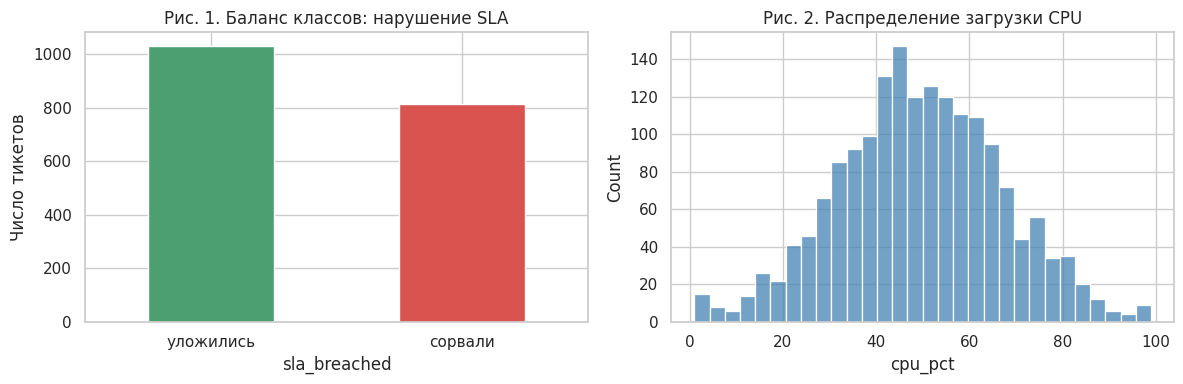

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_raw["sla_breached"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#4C9F70", "#D9534F"]
)
axes[0].set_title("Рис. 1. Баланс классов: нарушение SLA")
axes[0].set_xticklabels(["уложились", "сорвали"], rotation=0)
axes[0].set_ylabel("Число тикетов")

sns.histplot(df_raw["cpu_pct"].dropna(), bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("Рис. 2. Распределение загрузки CPU")
plt.tight_layout()
plt.show()


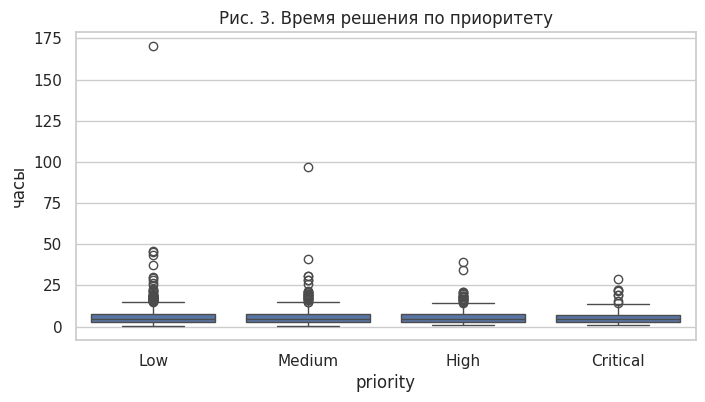

In [26]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_raw, x="priority", y="resolve_hours",
            order=["Low", "Medium", "High", "Critical"])
plt.title("Рис. 3. Время решения по приоритету")
plt.ylabel("часы")
plt.show()


### Задание 4

Постройте **не меньше четырёх разных типов** графиков по **своим** данным. Обязательно:

1. **Гистограмма** `resolve_hours` (видно ли выбросы справа?).
2. **Boxplot** `cpu_pct` в разрезе `sla_breached`.
3. **Тепловая карта** корреляций числовых столбцов (`corr(numeric_only=True)` + `sns.heatmap(..., annot=True)`).
4. **Столбчатая или круговая** диаграмма: доля нарушений SLA по `department` **или** по `product`.
5. По желанию пятый график (scatter `cpu_pct` vs `memory_mb`, stacked bar канала и SLA и т. п.).

После графиков напишите 2–3 вывода **по вашему SEED**, не общие фразы из учебника.


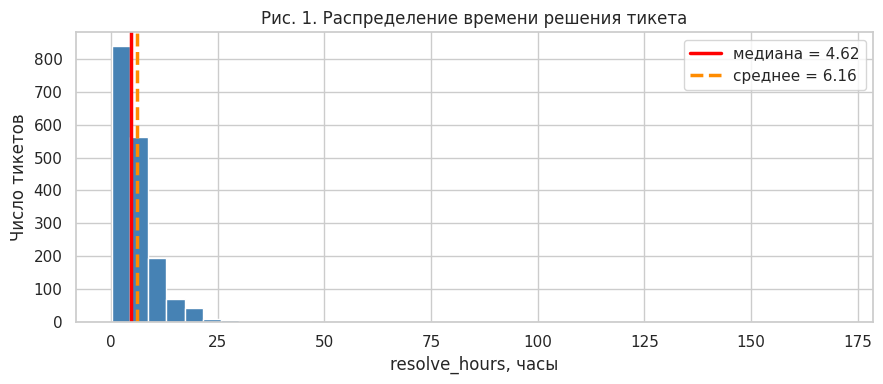

In [27]:
#  ВАШ КОД (Задание 4)

# График 1: гистограмма resolve_hours
s = df_raw["resolve_hours"].dropna()
med_ = s.median()
mean_ = s.mean()

plt.figure(figsize=(9, 4))
plt.hist(s, bins=40, color="steelblue", edgecolor="white")
plt.axvline(med_,  color="red",        linewidth=2.5,
            label=f"медиана = {med_:.2f}")
plt.axvline(mean_, color="darkorange", linewidth=2.5, linestyle="--",
            label=f"среднее = {mean_:.2f}")
plt.xlabel("resolve_hours, часы")
plt.ylabel("Число тикетов")
plt.title("Рис. 1. Распределение времени решения тикета")
plt.legend()
plt.tight_layout()
plt.show()



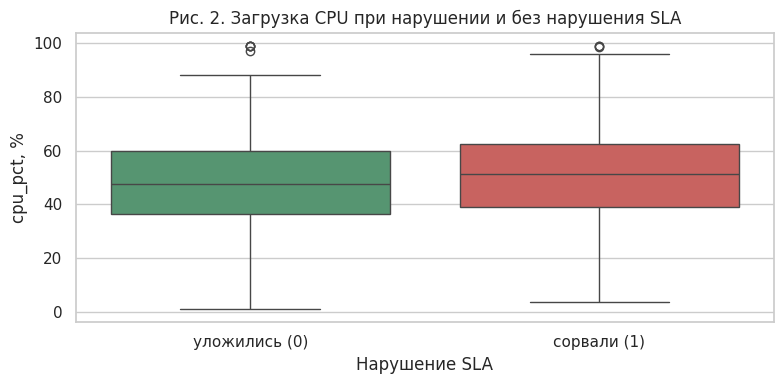

In [28]:
# График 2: boxplot cpu_pct по sla_breached
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_raw, x="sla_breached", y="cpu_pct",
            hue="sla_breached", palette=["#4C9F70", "#D9534F"], legend=False)
plt.xticks([0, 1], ["уложились (0)", "сорвали (1)"])
plt.xlabel("Нарушение SLA")
plt.ylabel("cpu_pct, %")
plt.title("Рис. 2. Загрузка CPU при нарушении и без нарушения SLA")
plt.tight_layout()
plt.show()


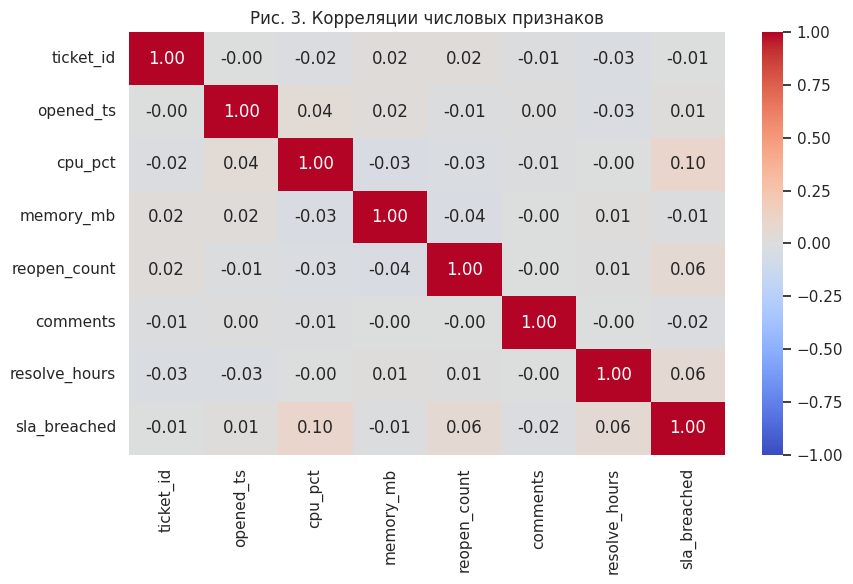

In [29]:
# График 3: тепловая карта корреляций
numeric_df = df_raw.select_dtypes(include="number")
correlation_matrix = numeric_df.corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Рис. 3. Корреляции числовых признаков")
plt.tight_layout()
plt.show()


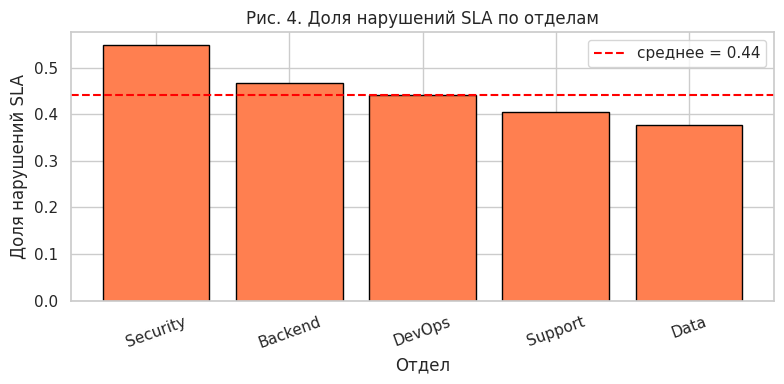

In [30]:
# График 4: доля SLA по отделу
df_raw["department_clean"] = (
    df_raw["department"].astype(str).str.strip().str.title()
    .replace({"Devops": "DevOps"}))

sla_by_dept = (df_raw.groupby("department_clean")["sla_breached"]
                     .mean().sort_values(ascending=False))

plt.figure(figsize=(8, 4))
plt.bar(sla_by_dept.index, sla_by_dept.values,
        color="coral", edgecolor="black")
plt.axhline(df_raw["sla_breached"].mean(), color="red", linestyle="--",
            label=f"среднее = {df_raw['sla_breached'].mean():.2f}")
plt.xlabel("Отдел")
plt.ylabel("Доля нарушений SLA")
plt.title("Рис. 4. Доля нарушений SLA по отделам")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()


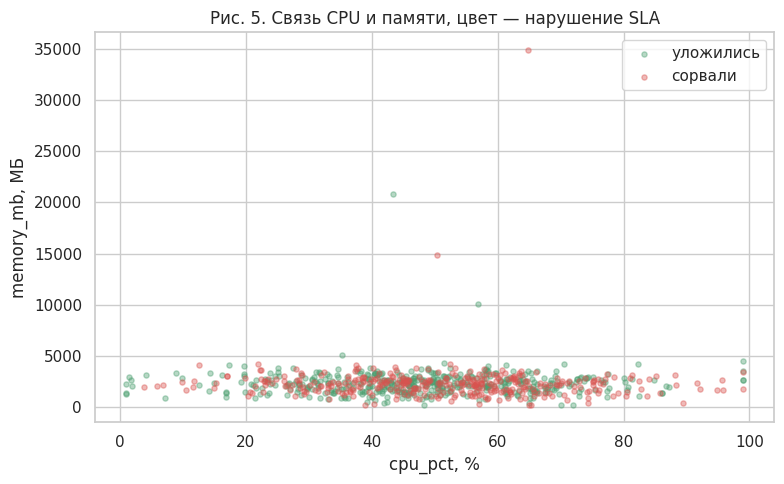

In [31]:
# График 5 (по желанию): scatter cpu_pct vs memory_mb
plot_df = df_raw[["cpu_pct", "memory_mb", "sla_breached"]].dropna()
plot_df = plot_df.sample(n=min(800, len(plot_df)), random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(plot_df.loc[plot_df["sla_breached"] == 0, "cpu_pct"],
            plot_df.loc[plot_df["sla_breached"] == 0, "memory_mb"],
            alpha=0.4, s=14, c="#4C9F70", label="уложились")
plt.scatter(plot_df.loc[plot_df["sla_breached"] == 1, "cpu_pct"],
            plot_df.loc[plot_df["sla_breached"] == 1, "memory_mb"],
            alpha=0.4, s=14, c="#D9534F", label="сорвали")
plt.xlabel("cpu_pct, %")
plt.ylabel("memory_mb, МБ")
plt.title("Рис. 5. Связь CPU и памяти, цвет — нарушение SLA")
plt.legend()
plt.tight_layout()
plt.show()
#  КОНЕЦ ВАШЕГО КОДА


**Выводы по графикам** (2–3 закономерности из ВАШИХ данных):

По времени решения (Рис. 1): Большинство тикетов закрываются очень быстро — в первые 10 часов. Но есть отдельные «долгожители», которые висят по 100–200 часов. Из-за этих редких, но долгих тикетов среднее время (6.16 ч) получается больше, чем реальное типичное время (медиана 4.62 ч). Поэтому для будущей модели нужно либо сгладить эти аномалии, либо ориентироваться на медиану.

На (Рис. 2) видно, что при нарушении SLA загрузка процессора в среднем немного выше (красный ящик сдвинут вверх по сравнению с зеленым). Высокая нагрузка на сервер действительно повышает риск задержки. Однако ящики сильно пересекаются: это значит, что одна только загрузка CPU не гарантирует срыв. Модель должна учитывать этот признак в связке с другими.

По связи цифр с целью (Рис. 3): Если смотреть на тепловую карту, ни загрузка процессора, ни память, ни количество переоткрытий сами по себе не предсказывают срыв SLA (все цифры около нуля). Модель не сможет сказать: «Ой, процессор загружен на 80%, значит, точно сорвут». Значит, предсказывать придется по совокупности факторов.

По отделам (Рис. 4): Отдел влияет на результат гораздо сильнее, чем любые цифры. Самый проблемный — отдел безопасности (Security), он срывает сроки в 54% случаев (при среднем 44%). А «Дата» (Data) наоборот работает лучше всех — срывов меньше 40%. Поэтому принадлежность к отделу будет очень важным подсказчиком для нашей модели.

По процессору и памяти (Рис. 5): На графике рассеяния точки «успешных» и «провальных» тикетов перемешаны в одну кучу (кроме пары выбросов по памяти вверху). Это еще раз подтверждает, что просто «большая нагрузка на сервер» не гарантирует срыв дедлайна — нужно учитывать другие обстоятельства.

**Контрольные вопросы к этапу 4:**

1. Что показывает boxplot и как по нему увидеть выброс?
2. Корреляция и причинно-следственная связь — в чём разница? Пример из IT-журнала.
3. Почему при редких нарушениях SLA одной accuracy на будущей модели может не хватить?



*Ответы:*

1. Что показывает boxplot и как по нему увидеть выброс?
Boxplot (ящик с усами) — это график, который показывает, как разбросаны данные, и помогает быстро найти аномалии (выбросы).

Как он устроен: Сам «ящик» показывает 50% самых типичных значений (от 25-го до 75-го процентиля). Черная линия внутри ящика — это медиана (самое типичное значение).

Усы и выбросы: Линии («усы»), выходящие из ящика, показывают границы нормального разброса. Выброс — это точки, которые вылетели далеко за пределы этих усов. На них смотрят в первую очередь, так как это либо ошибки датчика, либо редкие аномальные события.

Пример из нашей работы: На Рис. 2 (график CPU) мы видим кружочки над верхним усом. Это тикеты, где процессор был загружен под 100%. Это выбросы — перегрузка сервера, которая случается редко.

2. Корреляция и причинно-следственная связь — в чём разница? Пример из IT-журнала.
Корреляция — это математическая связь. Она говорит: «Когда X растет, Y тоже растет (или падает)». Но она не говорит, кто кого вызвал.

Причинно-следственная связь — это когда мы точно знаем, что изменение X привело к изменению Y.

Пример из IT-журнала: В нашей тепловой карте (Рис. 3) есть корреляция между загрузкой процессора (cpu_pct) и нарушением SLA (sla_breached). Но это не значит, что процессор «сломал» дедлайн. Возможны скрытые причины:

Скрытая переменная: Ночью админов мало (они спят), и тикетов приходит много. И процессор загружен из-за ночной нагрузки, и SLA срывается из-за нехватки людей. Процессор тут вообще ни при чем.
Обратная причинность: Сложная кибератака (тикет) сама по себе вызывает нагрузку на процессор, и она же приводит к срыву SLA.
Чтобы доказать причинность, нужен настоящий эксперимент (A/B-тест), а не просто наблюдение.
3. Почему при редких нарушениях SLA одной accuracy на будущей модели может не хватить?
Accuracy (Доля правильных ответов) — обманчивая метрика, если классы несбалансированы (одних случаев сильно больше, чем других).

В чём подвох: Если нарушения SLA случаются редко (например, в 10% случаев), модель-«обманка», которая вообще не будет учиться, а просто всегда будет отвечать «SLA не нарушен», получит Accuracy = 90%! Выглядит отлично, но такая модель бесполезна — она пропустит все реальные срывы.

Что использовать вместо этого:

Recall (Полнота): Какую долю реальных нарушений мы смогли поймать? (Для бизнеса это критично, если пропустить срыв дороже, чем поднять ложную тревогу).

Precision (Точность): Если модель сказала «будет срыв», то какова вероятность, что она не ошиблась?

F1-мера: Баланс между точностью и полнотой.

Confusion Matrix (Матрица ошибок): Наглядно показывает, сколько срывов мы поймали, а сколько пропустили (False Negative).

---
# Этап 5. Подготовка данных и признаки (практика 5)

**Цель.** Убрать дубликаты, закрыть пропуски, привести текст к одному виду, закодировать категории, масштабировать числа, собрать несколько новых признаков. Это тот же конвейер, что на практике 5, только на вашем журнале тикетов.

Работайте с копией: исходный `df_raw` не затирайте.


### Пример


In [32]:
df = df_raw.copy()
before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
print("Удалено дубликатов:", before - df.shape[0])
print("Пропуски по столбцам:")
print(df.isna().sum())

median_cpu = df["cpu_pct"].median()
df["cpu_pct"] = df["cpu_pct"].fillna(median_cpu)
print("Пропусков в cpu_pct после заполнения:", int(df["cpu_pct"].isna().sum()))


Удалено дубликатов: 45
Пропуски по столбцам:
ticket_id             0
opened_ts             0
department            0
product               0
priority              0
channel               0
assignee_level        0
client_tier           0
cpu_pct              72
memory_mb             0
reopen_count          0
comments             54
resolve_hours       108
sla_breached          0
is_slow               0
department_clean      0
dtype: int64
Пропусков в cpu_pct после заполнения: 0


In [33]:
# Текст: пробелы и регистр. Без этого Backend и BACKEND — разные категории.
demo = df["department"].astype(str).str.strip().str.title()
print("Уникальные отделы до:", df["department"].nunique())
print("После strip+title:", demo.nunique())
print(sorted(demo.unique()))


Уникальные отделы до: 10
После strip+title: 5
['Backend', 'Data', 'Devops', 'Security', 'Support']


### Задание 5

Начните заново с копии `df_raw`. Сохраните результат в `df_clean`, матрицу признаков в `X`, цель в `y`.

1. Удалите дубликаты.
2. Заполните пропуски: `resolve_hours` и `cpu_pct` — **медианой**, `comments` — **медианой** или нулём. Проверьте, что пропусков не осталось.
3. Приведите `department` и `product` к одному виду: `.str.strip()` и единый регистр (например `.str.title()`). Снова посчитайте число уникальных значений.
4. Закодируйте категории `department`, `product`, `priority`, `channel`, `assignee_level`, `client_tier` через `pd.get_dummies(...)`.
5. Создайте **не меньше трёх** осмысленных признаков, например:
   - `is_critical` — флаг приоритета Critical;
   - `load_score` — `cpu_pct * memory_mb / 1000`;
   - `reopen_rate` — `n_reopens / comments` (защититесь от деления на ноль);
   - свой признак (выходной ли день из `opened_ts`, «долгий тикет» и т. п.).
6. Отберите числовые столбцы (без `ticket_id` и `opened_ts`) и масштабируйте их `StandardScaler`. Сложите с dummy-признаками в `df_clean`.
7. Соберите `X` (всё, кроме `sla_breached` и идентификаторов) и `y = df_clean["sla_breached"]`. Напечатайте формы.


In [34]:
#  ВАШ КОД (Задание 5)
from sklearn.preprocessing import StandardScaler

df = df_raw.copy()

# 1–2. Дубликаты и пропуски
df = df.drop_duplicates().reset_index(drop=True)
df["resolve_hours"] = df["resolve_hours"].fillna(df["resolve_hours"].median())
df["cpu_pct"]       = df["cpu_pct"].fillna(df["cpu_pct"].median())
df["comments"]      = df["comments"].fillna(df["comments"].median())

# Проверка, что пропусков не осталось
print("Осталось пропусков (NaN):", df.isna().sum().sum())


Осталось пропусков (NaN): 0


In [35]:
# 3. Текст department и product
df["department"] = df["department"].str.strip().str.title()
df["product"]    = df["product"].str.strip().str.title()

print("Уникальных отделов (department):", df["department"].nunique())
print("Уникальных продуктов (product):", df["product"].nunique())

Уникальных отделов (department): 5
Уникальных продуктов (product): 5


In [36]:
# 4. get_dummies

cat_cols = ["department", "product", "priority", "channel", "assignee_level", "client_tier"]
# drop_first=True удаляет первый столбец каждой категории
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

In [37]:
# 5. Новые признаки (минимум 3, один — свой)
# 5.1. Флаг критического приоритета
# Так как drop_first=True удалил priority_Critical, мы понимаем, что это Critical,
# если все остальные флаги приоритета равны 0.
df["is_critical"] = (
    (df["priority_High"] == 0) &
    (df["priority_Low"] == 0) &
    (df["priority_Medium"] == 0)
).astype(int)

# 5.2. Нагрузочный скор
df["load_score"] = df["cpu_pct"] * df["memory_mb"] / 1000

# 5.3. Доля переоткрытий (защита от деления на ноль)
safe_comments = df["comments"].replace(0, np.nan)
reopen_col = "reopen_count" if "reopen_count" in df.columns else "n_reopens"
df["reopen_rate"] = (df[reopen_col] / safe_comments).fillna(0)

# 5.4. Свой признак: выходной ли день
df["is_weekend"] = (pd.to_datetime(df["opened_ts"], unit="s").dt.dayofweek >= 5).astype(int)

print("Новые признаки созданы!")


Новые признаки созданы!


In [38]:
# 6–7. Масштаб, df_clean, X, y
num_cols = ["cpu_pct", "memory_mb", "resolve_hours", reopen_col, "comments", "load_score", "reopen_rate"]

scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df[num_cols]),
    columns=num_cols,
    index=df.index
)

# Собираем df_clean: dummy-столбцы + флаги + масштабированные числа + цель
dummy_cols = [c for c in df.columns if c.startswith(tuple(cat_cols))]
flag_cols  = ["is_critical", "is_weekend"]

df_clean = pd.concat([df[dummy_cols + flag_cols], df_scaled, df["sla_breached"]], axis=1)

X = df_clean.drop(columns=["sla_breached"])
y = df_clean["sla_breached"]

print("Размер X:", X.shape, "| Размер y:", y.shape)
#  КОНЕЦ ВАШЕГО КОДА


Размер X: (1800, 28) | Размер y: (1800,)


**Контрольные вопросы к этапу 5:**

1. Когда для пропусков берут медиану, а когда среднее?
2. Что такое One-Hot (`get_dummies`) и почему отделы нельзя просто заменить числами 1, 2, 3…?
3. Зачем масштабировать признаки перед линейными моделями и kNN и почему дереву это обычно не нужно?
4. Почему `ticket_id` нельзя подавать в модель как обычный признак?


*Ответы:*

1. Выбор зависит от того, есть ли в данных выбросы (аномально большие или маленькие значения) и как выглядит распределение.

Среднее берут, когда данные распределены симметрично (как колокол), без сильных выбросов. В этом случае среднее хорошо показывает центр.

Медиану берут, когда в данных есть выбросы или распределение «скошено» в одну сторону.

Пример из нашей работы: Время решения тикета (resolve_hours) имеет длинный хвост из-за «долгожителей» (тикетов, которые висят по 150+ часов). Если мы посчитаем среднее, эти редкие долгие тикеты сильно задерут его вверх, и оно перестанет быть похожим на реальность. Медиана же (центральное значение) устойчива к таким выбросам, поэтому для заполнения пропусков в этом столбце мы выбрали её.

2. One-Hot Encoding — это способ превратить текстовые категории в числа, создав для каждой категории отдельный столбец с флагами 1 (есть признак) и 0 (нет признака).

Почему нельзя просто написать 1, 2, 3:

Модели машинного обучения — это математика. Если вы напишете Support = 1, Backend = 2, Security = 3, линейная модель или нейросеть подумает, что Security в 3 раза больше Support (ведь 3 > 1).

Это создаст ложную иерархию, которой в реальности не существует. Отдел безопасности не «главнее» отдела поддержки, они просто разные.

One-Hot решает эту проблему: он делает все отделы равноправными. Модель видит отдельные независимые флаги: department_Security = 1, department_Support = 0 и т.д.

3. Линейные модели и kNN (метод ближайших соседей): Они очень чувствительны к масштабу чисел.

Пример: У нас есть загрузка CPU (от 1 до 100) и память (от 256 до 50 000 МБ). Если мы не отмасштабируем данные, при расчете расстояний (в kNN) или весов (в линейной модели) память полностью «заглушит» процессор. Модель просто не заметит изменений в CPU, потому что на фоне 50 000 разница в 50 единиц — это ничто. StandardScaler приводит все признаки к единому масштабу (среднее 0, разброс 1).

Деревья решений (Random Forest, Decision Tree): Им масштаб не важен, потому что они работают не с расстояниями, а с порогами. Дереву всё равно, сравнивать ли cpu_pct > 50 или cpu_pct > 0.5 — логика разбиения не изменится. Ему важен порядок значений, а не их абсолютная величина.

4. Это не признак, а идентификатор. Он уникален для каждой строки и не несет в себе физического смысла о самом тикете (не описывает его приоритет, сложность или отдел).

Риск переобучения (Overfitting). Если дать модели ticket_id, она может просто «зазубрить» ответы: «Если ID = 10045, то SLA = 1». На обучающей выборке она покажет идеальный результат, но когда придет новый тикет с ID = 20000, модель не сможет ничего предсказать, так как этого номера не было в ее памяти.

Отсутствие обобщающей способности. Модель должна искать закономерности в данных (например, «критичные тикеты сорывают SLA чаще»), а не запоминать номера заказов. Поэтому ticket_id мы исключили из матрицы X.

---
# Итоговый отчёт студента

Заполните по **вашему** варианту. Это обязательная часть (без отчёта работа не принимается).


### Данные варианта

| Поле | Значение |
|------|----------|
| ФИО |  |
| Номер по списку |  |
| Персональный SEED |  |
| Строк в `df_raw` |  |
| Строк после удаления дубликатов |  |
| Доля `sla_breached` |  |
| Размер `X` (строки × столбцы) |  |

### Кратко по этапам

1. Что необычного увидели при осмотре (типы, дубликаты, пропуски)?
2. Какой отдел / продукт / приоритет чаще ломает SLA на ваших графиках?
3. Какие три новых признака сделали и зачем?


### Финальная самопроверка

Ячейка ниже не ставит оценку, а подсказывает, какие переменные ещё не созданы.


In [39]:
problems = []

if "SEED" not in dir():
    problems.append("Не вычислен SEED (шаг 0).")
if "df_raw" not in dir():
    problems.append("Не создан df_raw (генерация датасета).")
if "df_clean" not in dir() or df_clean is None:
    problems.append("Не создан df_clean (этап 5).")
if "X" not in dir() or X is None:
    problems.append("Не создана матрица X (этап 5).")
if "y" not in dir() or y is None:
    problems.append("Не создан вектор y (этап 5).")
if "df_clean" in dir() and df_clean is not None:
    n_na = int(df_clean.isna().sum().sum())
    if n_na > 0:
        problems.append(f"В df_clean ещё есть пропуски: {n_na}.")

if problems:
    print("Ещё не готово:")
    for item in problems:
        print(" -", item)
else:
    print("Базовые переменные на месте. Проверьте текстовые ответы и отчёт.")
    print("SEED:", SEED, "| X:", X.shape, "| y:", y.shape)


Базовые переменные на месте. Проверьте текстовые ответы и отчёт.
SEED: 36390 | X: (1800, 28) | y: (1800,)


---
### Как сдать работу

1. Запустите все ячейки **сверху вниз** без ошибок (`Среда выполнения → Перезапустить и выполнить всё`).
2. Заполните код заданий, контрольные вопросы и итоговый отчёт.
3. Сохраните файл: `Файл → Скачать → Скачать .ipynb`.
4. Переименуйте в `Фамилия_Имя_ПР6.ipynb` и загрузите в Moodle.

Шкала: 5 блоков = **14 баллов**. Пустой шаблон без запуска не оценивается.
